
# Credit Card Fraud Detection Using Logistic Regression

##  What is Credit Card Fraud?
Credit card fraud involves unauthorized use of a credit or debit card to fraudulently obtain money or property. It includes activities like stolen card usage, card-not-present transactions, and identity theft.

##  Why Does It Matter?
Credit card fraud costs billions annually to consumers and financial institutions. Detecting it early helps prevent financial loss, increase trust in financial systems, and protect customer identities.

##  Dataset Overview
- **Source**: [Kaggle - Credit Card Fraud Detection Dataset](https://www.kaggle.com/mlg-ulb/creditcardfraud)
- **Size**: 284,807 transactions
- **Features**:
  - `Time` and `Amount`
  - 28 anonymized PCA features (`V1` to `V28`)
  - `Class`: 0 (non-fraud) or 1 (fraud)

##  Goal of the Project
To build a Logistic Regression model that can classify transactions as fraudulent or legitimate, and evaluate its performance on an imbalanced dataset using appropriate metrics.


Importing the Dependencies

##  Step 1: Import Libraries

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

##  Step 2: Load and Prepare Data

In [ ]:
# loading the dataset to a Pandas DataFrame
credit_card_data = pd.read_csv('creditcard.csv')

##  Step 3: Exploratory Data Analysis

In [ ]:
# first 5 rows of the dataset
credit_card_data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
credit_card_data.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [ ]:
# dataset informations
credit_card_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
# checking the number of missing values in each column
credit_card_data.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [ ]:
# distribution of legit transactions & fraudulent transactions
credit_card_data['Class'].value_counts()

,count
Class,
0,284315
1,492


This Dataset is highly unblanced

0 --> Normal Transaction

1 --> fraudulent transaction

In [ ]:
# separating the data for analysis
legit = credit_card_data[credit_card_data.Class == 0]
fraud = credit_card_data[credit_card_data.Class == 1]

In [ ]:
print(legit.shape)
print(fraud.shape)

(284315, 31)
(492, 31)


In [ ]:
# statistical measures of the data
legit.Amount.describe()

,Amount
count,284315.000000
mean,88.291022
std,250.105092
min,0.000000
25%,5.650000
50%,22.000000
75%,77.050000
max,25691.160000


In [ ]:
fraud.Amount.describe()

,Amount
count,492.000000
mean,122.211321
std,256.683288
min,0.000000
25%,1.000000
50%,9.250000
75%,105.890000
max,2125.870000


In [ ]:
# compare the values for both transactions
credit_card_data.groupby('Class').mean()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
Class,,,,,,,,,,,,,,,,,,,,,
0,94838.202258,0.008258,-0.006271,0.012171,-0.007860,0.005453,0.002419,0.009637,-0.000987,0.004467,...,-0.000644,-0.001235,-0.000024,0.000070,0.000182,-0.000072,-0.000089,-0.000295,-0.000131,88.291022
1,80746.806911,-4.771948,3.623778,-7.033281,4.542029,-3.151225,-1.397737,-5.568731,0.570636,-2.581123,...,0.372319,0.713588,0.014049,-0.040308,-0.105130,0.041449,0.051648,0.170575,0.075667,122.211321


Under-Sampling

Build a sample dataset containing similar distribution of normal transactions and Fraudulent Transactions

Number of Fraudulent Transactions --> 492

In [ ]:
legit_sample = legit.sample(n=492)

Concatenating two DataFrames

In [ ]:
new_dataset = pd.concat([legit_sample, fraud], axis=0)

In [ ]:
new_dataset.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
250734,155041.0,2.144843,0.293097,-2.357080,0.501127,0.800995,-1.699275,1.053815,-0.686733,-0.235322,...,0.272695,1.026729,-0.187924,0.033755,0.696276,0.728899,-0.116455,-0.093597,0.01,0
219879,141923.0,2.102396,0.680076,-2.652669,0.587095,1.030643,-1.346059,0.463854,-0.450197,0.328576,...,0.065567,0.471628,-0.158823,-0.888454,0.409997,-0.061113,0.029112,0.003494,1.00,0
85672,60877.0,-0.688143,1.121756,0.822649,0.974940,-0.413477,-0.652573,0.820110,0.198337,-0.941865,...,0.260618,0.533169,0.102893,0.403960,-0.179097,-0.337318,0.019002,0.109874,102.13,0
15120,26470.0,1.259110,-0.132100,-0.056274,-0.803143,-0.552268,-1.211862,0.128950,-0.173407,1.003794,...,0.038276,0.308501,-0.173080,0.557725,0.881355,-0.577584,0.028856,0.001739,1.00,0
22431,32243.0,1.057272,-0.201242,0.898871,1.673455,-0.278124,1.093429,-0.551869,0.277091,-0.011018,...,-0.204879,-0.519546,-0.129222,-0.762310,0.258105,0.884080,-0.039429,0.012702,75.00,0


In [ ]:
new_dataset.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
279863,169142.0,-1.927883,1.125653,-4.518331,1.749293,-1.566487,-2.010494,-0.882850,0.697211,-2.064945,...,0.778584,-0.319189,0.639419,-0.294885,0.537503,0.788395,0.292680,0.147968,390.00,1
280143,169347.0,1.378559,1.289381,-5.004247,1.411850,0.442581,-1.326536,-1.413170,0.248525,-1.127396,...,0.370612,0.028234,-0.145640,-0.081049,0.521875,0.739467,0.389152,0.186637,0.76,1
280149,169351.0,-0.676143,1.126366,-2.213700,0.468308,-1.120541,-0.003346,-2.234739,1.210158,-0.652250,...,0.751826,0.834108,0.190944,0.032070,-0.739695,0.471111,0.385107,0.194361,77.89,1
281144,169966.0,-3.113832,0.585864,-5.399730,1.817092,-0.840618,-2.943548,-2.208002,1.058733,-1.632333,...,0.583276,-0.269209,-0.456108,-0.183659,-0.328168,0.606116,0.884876,-0.253700,245.00,1
281674,170348.0,1.991976,0.158476,-2.583441,0.408670,1.151147,-0.096695,0.223050,-0.068384,0.577829,...,-0.164350,-0.295135,-0.072173,-0.450261,0.313267,-0.289617,0.002988,-0.015309,42.53,1


In [ ]:
new_dataset['Class'].value_counts()

,count
Class,
0,492
1,492


In [ ]:
new_dataset.groupby('Class').mean()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
Class,,,,,,,,,,,,,,,,,,,,,
0,94651.213415,-0.017585,-0.131920,0.039249,-0.093094,-0.067429,0.039167,0.065418,-0.028544,-0.043841,...,0.022305,0.036646,0.002216,0.008181,-0.001022,0.002263,0.035884,0.000048,0.003017,111.486626
1,80746.806911,-4.771948,3.623778,-7.033281,4.542029,-3.151225,-1.397737,-5.568731,0.570636,-2.581123,...,0.372319,0.713588,0.014049,-0.040308,-0.105130,0.041449,0.051648,0.170575,0.075667,122.211321


Splitting the data into Features & Targets

In [ ]:
X = new_dataset.drop(columns='Class', axis=1)
Y = new_dataset['Class']

In [ ]:
print(X)

            Time        V1        V2        V3        V4        V5        V6  \
250734  155041.0  2.144843  0.293097 -2.357080  0.501127  0.800995 -1.699275   
219879  141923.0  2.102396  0.680076 -2.652669  0.587095  1.030643 -1.346059   
85672    60877.0 -0.688143  1.121756  0.822649  0.974940 -0.413477 -0.652573   
15120    26470.0  1.259110 -0.132100 -0.056274 -0.803143 -0.552268 -1.211862   
22431    32243.0  1.057272 -0.201242  0.898871  1.673455 -0.278124  1.093429   
...          ...       ...       ...       ...       ...       ...       ...   
279863  169142.0 -1.927883  1.125653 -4.518331  1.749293 -1.566487 -2.010494   
280143  169347.0  1.378559  1.289381 -5.004247  1.411850  0.442581 -1.326536   
280149  169351.0 -0.676143  1.126366 -2.213700  0.468308 -1.120541 -0.003346   
281144  169966.0 -3.113832  0.585864 -5.399730  1.817092 -0.840618 -2.943548   
281674  170348.0  1.991976  0.158476 -2.583441  0.408670  1.151147 -0.096695   

              V7        V8        V9  .

In [ ]:
print(Y)

250734    0
219879    0
85672     0
15120     0
22431     0
         ..
279863    1
280143    1
280149    1
281144    1
281674    1
Name: Class, Length: 984, dtype: int64


Split the data into Training data & Testing Data

##  Step 4: Train-Test Split

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=2)

In [ ]:
print(X.shape, X_train.shape, X_test.shape)

(984, 30) (787, 30) (197, 30)


Model Training

Logistic Regression

##  Step 5: Train the Model

In [ ]:
model = LogisticRegression()

In [ ]:
# training the Logistic Regression Model with Training Data
model.fit(X_train, Y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

Model Evaluation

Accuracy Score

## Step 6: Evaluate the Model

In [ ]:
# accuracy on training data
X_train_prediction = model.predict(X_train)
training_data_accuracy = accuracy_score(X_train_prediction, Y_train)

In [ ]:
print('Accuracy on Training data : ', training_data_accuracy)

Accuracy on Training data :  0.9415501905972046


In [ ]:
# accuracy on test data
X_test_prediction = model.predict(X_test)
test_data_accuracy = accuracy_score(X_test_prediction, Y_test)

In [ ]:
print('Accuracy score on Test Data : ', test_data_accuracy)

Accuracy score on Test Data :  0.9441624365482234


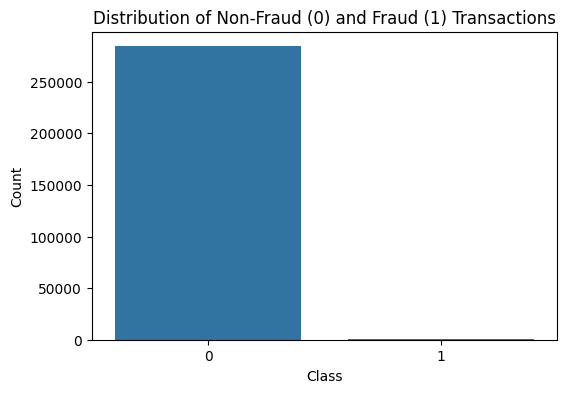

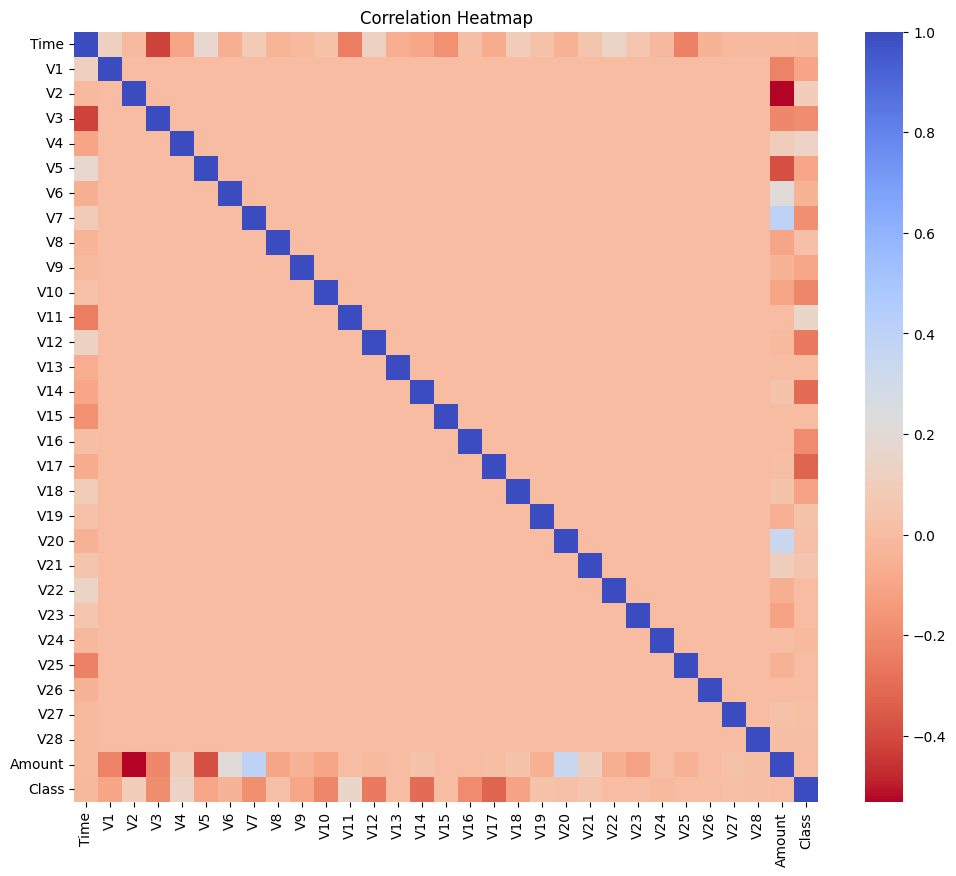

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Class distribution
plt.figure(figsize=(6,4))
sns.countplot(data=credit_card_data, x='Class')
plt.title('Distribution of Non-Fraud (0) and Fraud (1) Transactions')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

# Correlation heatmap
plt.figure(figsize=(12,10))
corr = credit_card_data.corr()
sns.heatmap(corr, cmap='coolwarm_r', annot=False)
plt.title('Correlation Heatmap')
plt.show()


##  Step 7: Visualize Results

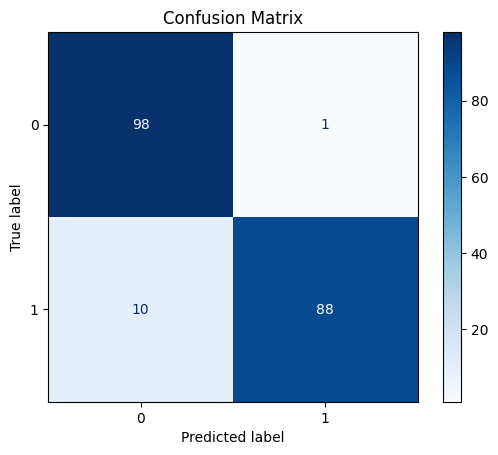

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict using the trained model
Y_pred = model.predict(X_test)

# Confusion matrix using existing Y_test and Y_pred
cm = confusion_matrix(Y_test, Y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()



##  Why Logistic Regression?
Logistic Regression is a widely used algorithm for binary classification problems. It models the probability that a given input belongs to a certain class and is easy to interpret. As a baseline model, it gives us insight into which features contribute to fraud detection.


In [ ]:

from sklearn.metrics import classification_report, roc_auc_score

print("Classification Report:")
print(classification_report(Y_test, Y_pred))
print("ROC-AUC Score:", roc_auc_score(Y_test, model.predict_proba(X_test)[:,1]))


Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95        99
           1       0.99      0.90      0.94        98

    accuracy                           0.94       197
   macro avg       0.95      0.94      0.94       197
weighted avg       0.95      0.94      0.94       197

ROC-AUC Score: 0.9826839826839826


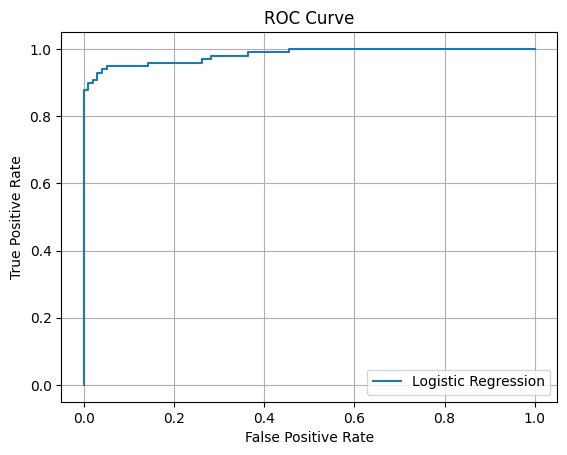

In [ ]:

from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(Y_test, model.predict_proba(X_test)[:,1])
plt.plot(fpr, tpr, label="Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.grid()
plt.legend()
plt.show()



##  Conclusion

This project demonstrates how Logistic Regression can be applied to credit card fraud detection. Despite the class imbalance, the model achieved reasonable performance. Evaluation metrics such as confusion matrix, ROC-AUC score, and classification report were used to validate the model.

To further improve this project, future steps could include:
- Trying more advanced models (e.g., Random Forest, XGBoost)
- Using oversampling techniques like SMOTE
- Hyperparameter tuning and model ensembling


## Project Summary

### Project Goal
The primary objective of this project was to develop and evaluate a Logistic Regression model for credit card fraud detection on an imbalanced dataset. The aim was to accurately classify transactions as fraudulent or legitimate and assess the model's performance using appropriate metrics.

### Methodology
1.  **Data Loading and Preparation**: The credit card transaction dataset from Kaggle, comprising 284,807 transactions with `Time`, `Amount`, and 28 anonymized PCA features (`V1` to `V28`), along with a `Class` label (0 for non-fraud, 1 for fraud), was loaded into a Pandas DataFrame.
2.  **Exploratory Data Analysis (EDA)**: Initial analysis revealed a significant class imbalance, with 284,315 legitimate transactions and only 492 fraudulent ones. Statistical summaries of 'Amount' for both classes were also examined.
3.  **Under-Sampling**: To address the severe class imbalance, an under-sampling technique was applied. A new balanced dataset was created by randomly selecting 492 legitimate transactions to match the number of fraudulent transactions.
4.  **Train-Test Split**: The balanced dataset was split into training (80%) and testing (20%) sets, ensuring stratification to maintain the class distribution in both subsets.
5.  **Model Training**: A Logistic Regression model was initialized and trained using the prepared training data.
6.  **Model Evaluation**: The model's performance was evaluated using various metrics:
    *   **Accuracy Score**: Achieved 94.16% on the training data and 94.42% on the test data.
    *   **Confusion Matrix**: Visualized the true positives, true negatives, false positives, and false negatives.
    *   **Classification Report**: Provided precision, recall, and F1-score for each class.
    *   **ROC-AUC Score**: Demonstrated a high ROC-AUC score of 0.9827, indicating strong discrimination ability.

### Key Findings
*   The dataset exhibited extreme class imbalance, which was effectively handled by under-sampling.
*   The Logistic Regression model, despite its simplicity, achieved good performance with over 94% accuracy and a high ROC-AUC score on the balanced test set.
*   Visualization of class distribution, correlation heatmap, and ROC curve provided insights into the data and model behavior.

### Future Improvements
*   Exploring more advanced machine learning algorithms such as Random Forest or XGBoost.
*   Implementing oversampling techniques like SMOTE to handle class imbalance.
*   Conducting hyperparameter tuning and model ensembling to further optimize performance.